# Quality Control and Preprocessing

This notebook documents quality control, gene filtering, normalization, and highly variable gene selection for the selected GSE131907 lung tumor samples. Run it from the repository root.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import yaml
from anndata import read_h5ad
from IPython.display import display

if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

with open("configs/default.yml") as file:
    config = yaml.safe_load(file)

sample_order = config["dataset"]["selected_samples"]
settings = config["preprocessing"]
figure_dir = "outputs/figures"

os.makedirs(figure_dir, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")

# Load the preprocessing outputs without repeating transformation steps.
qc_metrics = pd.read_csv("data/processed/lung_tumor_qc_metrics.csv.gz")
qc_metrics["sample"] = pd.Categorical(
    qc_metrics["sample"],
    categories=sample_order,
    ordered=True
)
sample_summary = pd.read_csv("outputs/tables/preprocessing-sample-summary.csv", index_col=0)
sample_summary = sample_summary.reindex(sample_order)
filtering_summary = pd.read_csv("outputs/tables/preprocessing-filtering-summary.csv")
gene_metrics = pd.read_csv("data/processed/lung_tumor_gene_qc_metrics.csv.gz")
hvg_metrics = pd.read_csv("data/processed/lung_tumor_hvg_metrics.csv.gz", index_col=0)
adata = read_h5ad("data/processed/lung_tumor_hvg.h5ad")

## Cell-level QC metrics

For cell $i$, we can derive the following quantitlies:

- total UMI counts: $c_i = \sum_g x_{ig}$
- detected genes: $n_i = \sum_g \mathbb{1}(x_{ig} > 0)$
- mitochondrial percentage: $p_i^{mt} = 100 \sum_{g \in MT} x_{ig}/c_i$

The quality control criteria are as follows: 

- $1000 \leq c_i \leq 100000$
- $300 \leq n_i \leq 10000$
- $p_i^{mt} \leq 15$

Here's a brief explanation of the rationale behind these criteria:

- The UMI and detected-gene lower bounds remove low-information libraries, which are often associated with cell death or lysis.
- The UMI and detected-gene upper bounds remove doublets, which are two cells that were captured together and sequenced as one.
- The mitochondrial upper bound removes cells with a high fraction of mitochondrial transcripts, which is often associated with cell death or lysis.
- No mitochondrial lower bound is used because low mitochondrial expression is not a standard low-quality signal.

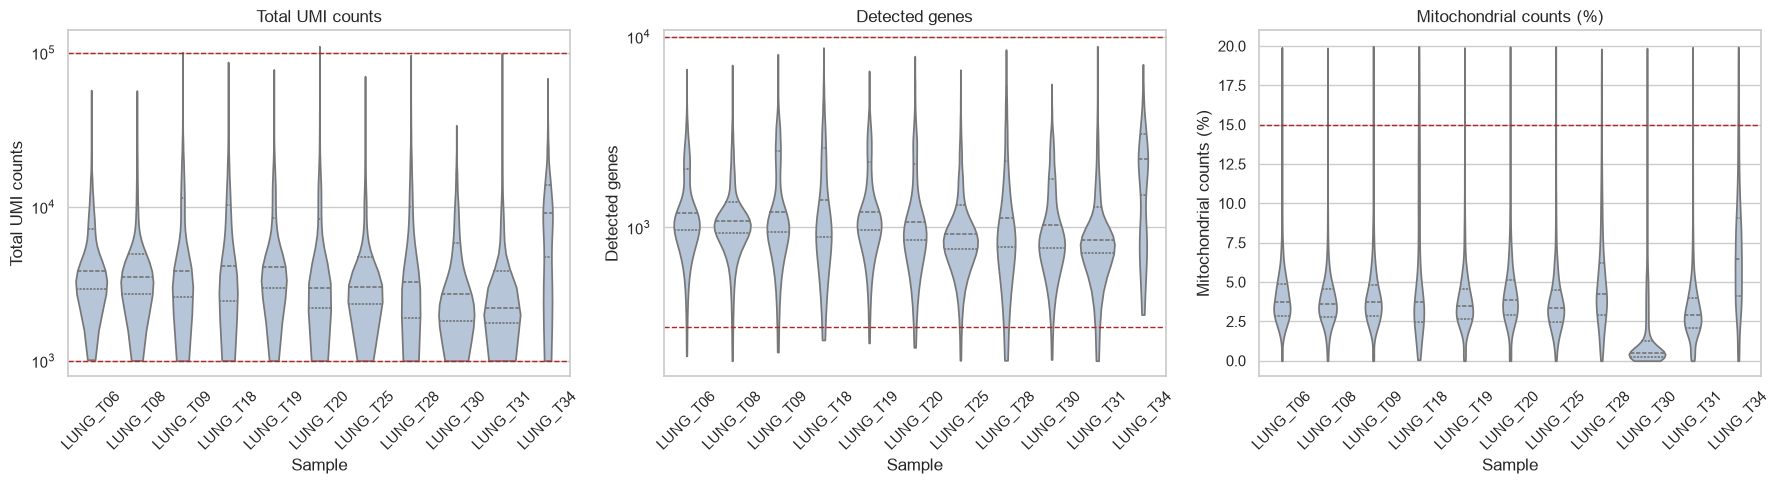

In [2]:
# Compare the raw metric distributions with the shared thresholds.
metrics = [
    ("total_counts", "Total UMI counts", True, [settings["min_total_counts"], settings["max_total_counts"]]),
    ("n_genes_by_counts", "Detected genes", True, [settings["min_genes_per_cell"], settings["max_genes_per_cell"]]),
    ("pct_counts_mt", "Mitochondrial counts (%)", False, [settings["max_mito_percent"]])
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for axis, (metric, label, log_scale, thresholds) in zip(axes, metrics):
    sns.violinplot(
        data=qc_metrics,
        x="sample",
        y=metric,
        order=sample_order,
        cut=0,
        inner="quartile",
        color="lightsteelblue",
        ax=axis
    )
    axis.set_title(label)
    axis.set_xlabel("Sample")
    axis.set_ylabel(label)
    axis.tick_params(axis="x", rotation=45)
    if log_scale:
        axis.set_yscale("log")
    for threshold in thresholds:
        axis.axhline(threshold, color="firebrick", linestyle="--", linewidth=1)

fig.tight_layout()
fig.savefig(
    os.path.join(figure_dir, "preprocessing-qc-metrics.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Filtering results

Cell filtering is applied with the same rule to every sample. Gene filtering is then applied only to cells that passed cell-level QC.

For gene $g$, detection frequency is $d_g = \sum_i \mathbb{1}(x_{ig} > 0)$ among retained cells. Genes with $d_g < 3$ are removed because their sparse occurrence provides little stable information for representation learning.

,cells_before_filtering,cells_after_cell_filtering,cell_retention_percent,genes_before_filtering,genes_after_gene_filtering,selected_hvgs
0,45149,44180,97.85,29634,24270,2000


,cells_before,median_total_counts_before,median_detected_genes_before,median_mito_percent_before,cells_after,median_total_counts_after,median_detected_genes_after,median_mito_percent_after,retention_percent
sample,,,,,,,,,
LUNG_T06,3426,3837.5,1194.5,3.72,3399,3840.0,1196.0,3.71,99.21
LUNG_T08,3765,3479.0,1082.0,3.60,3724,3480.5,1082.0,3.58,98.91
LUNG_T09,3840,3807.5,1197.0,3.71,3802,3818.5,1201.0,3.71,99.01
LUNG_T18,3705,4096.0,1386.0,3.71,3439,3791.0,1306.0,3.52,92.82
LUNG_T19,4361,4053.0,1198.0,3.47,4328,4059.0,1198.0,3.46,99.24
LUNG_T20,4021,2966.0,1073.0,3.86,3975,2949.0,1069.0,3.84,98.86
LUNG_T25,4374,3016.0,927.0,3.36,4329,3026.0,928.0,3.36,98.97
LUNG_T28,4705,3258.0,1126.0,4.27,4564,3253.0,1119.0,4.23,97.00
LUNG_T30,4094,2697.0,1026.0,0.51,4073,2710.0,1029.0,0.51,99.49


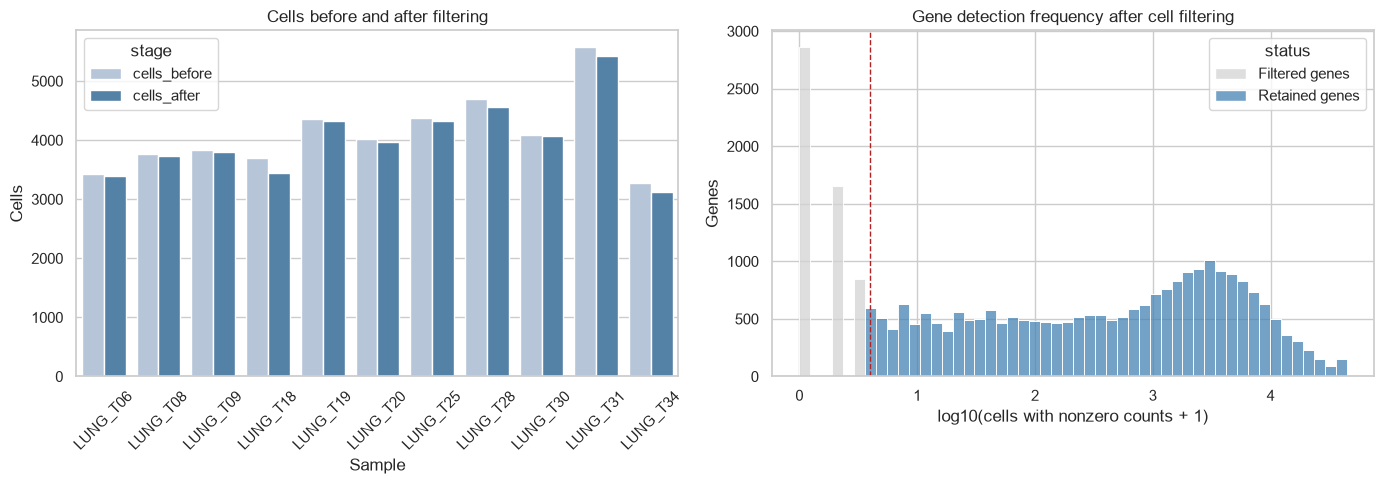

In [3]:
display(filtering_summary)
display(sample_summary)

# Compare sample-level cell retention with gene detection frequency.
cell_counts = (
    sample_summary[["cells_before", "cells_after"]]
    .reset_index(names="sample")
    .melt(id_vars="sample", var_name="stage", value_name="cells")
)
gene_plot = gene_metrics.copy()
gene_plot["status"] = np.where(
    gene_plot["passed_gene_filter"],
    "Retained genes",
    "Filtered genes"
)
gene_plot["log_detected_cells"] = np.log10(gene_plot["n_cells_by_counts"] + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(
    data=cell_counts,
    x="sample",
    y="cells",
    hue="stage",
    order=sample_order,
    palette=["lightsteelblue", "steelblue"],
    ax=axes[0]
)
axes[0].set_title("Cells before and after filtering")
axes[0].set_xlabel("Sample")
axes[0].set_ylabel("Cells")
axes[0].tick_params(axis="x", rotation=45)

sns.histplot(
    data=gene_plot,
    x="log_detected_cells",
    hue="status",
    hue_order=["Filtered genes", "Retained genes"],
    multiple="stack",
    bins=50,
    palette={"Filtered genes": "lightgray", "Retained genes": "steelblue"},
    ax=axes[1]
)
axes[1].axvline(
    np.log10(settings["min_cells_per_gene"] + 1),
    color="firebrick",
    linestyle="--",
    linewidth=1
)
axes[1].set_title("Gene detection frequency after cell filtering")
axes[1].set_xlabel("log10(cells with nonzero counts + 1)")
axes[1].set_ylabel("Genes")

fig.tight_layout()
fig.savefig(
    os.path.join(figure_dir, "preprocessing-filtering-results.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

## Normalization and highly variable genes

**Normalization:**

For each retained cell, expression is scaled to a common library size with $\tilde{x}_{ig} = 10000x_{ig}/c_i$, then transformed as $y_{ig} = \log(1 + \tilde{x}_{ig})$. This makes cells with different library sizes more comparable.

**Highly variable genes:**

For sample $s$ and gene $g$, let $\mu_{gs}$ and $\sigma^2_{gs}$ be the mean and variance of $y_{ig}$ across cells in $s$. Its dispersion is $d_{gs} = \sigma^2_{gs}/\mu_{gs}$.

Within a small bin $b$ of genes with similar $\mu_{gs}$, the standardized dispersion is $z_{gs} = (d_{gs} - \bar{d}_{bs})/\operatorname{sd}(d_{bs})$. A gene is provisionally selected within sample $s$ when its $z_{gs}$ is among that sample's highest values.

Across samples, genes are ranked by the number of provisional selections, then by $\bar{z}_g = 11^{-1}\sum_s z_{gs}$. The top 2,000 genes are retained.

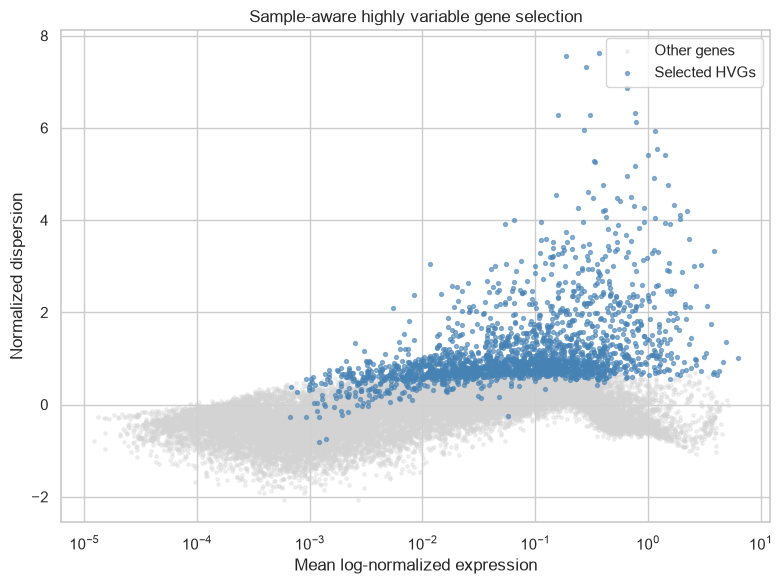

Cells after cell filtering: 44,180
Selected HVGs: 2,000


In [4]:
# Display the genes selected from the sample-aware dispersion ranking.
plot_data = hvg_metrics.dropna(subset=["means", "dispersions_norm"]).copy()

fig, axis = plt.subplots(figsize=(8, 6))
axis.scatter(
    plot_data.loc[~plot_data["highly_variable"], "means"],
    plot_data.loc[~plot_data["highly_variable"], "dispersions_norm"],
    s=6,
    alpha=0.3,
    color="lightgray",
    label="Other genes"
)
axis.scatter(
    plot_data.loc[plot_data["highly_variable"], "means"],
    plot_data.loc[plot_data["highly_variable"], "dispersions_norm"],
    s=8,
    alpha=0.6,
    color="steelblue",
    label="Selected HVGs"
)
axis.set_xscale("log")
axis.set_title("Sample-aware highly variable gene selection")
axis.set_xlabel("Mean log-normalized expression")
axis.set_ylabel("Normalized dispersion")
axis.legend()

fig.tight_layout()
fig.savefig(
    os.path.join(figure_dir, "preprocessing-hvg-selection.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"Cells after cell filtering: {adata.n_obs:,}")
print(f"Selected HVGs: {adata.n_vars:,}")

The resulting AnnData object is the common input for the PCA and autoencoder comparison. It contains normalized and log-transformed expression for the selected HVGs, while the original full-gene count matrix remains unchanged.